# Project #2, Part 2: Web Scraped Data Analysis and Visualizations

Name: Ananth Kashibhatla

Date: 4 November 2026

Purpose: To explore the first five Hacker News pages with built-in pandas functions, perform data preprocessing/cleaning as well as basic EDA with points, domains and comments

## 1. Import relevant libraries

In [75]:
import time 
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.parse import urlparse

## Create a function block to scrape one page from Hacker News

This function block will receive a page number and then return how many stories are trending within that page 

In [76]:
# Create a function block to scrape per page how many stories are there and how many pages are there in total.
def get_total_pages_and_stories(hacker_page_number): 
    # Create a hacker url to store the url of the hacker news page
    hacker_url = f"https://news.ycombinator.com/news?p={hacker_page_number}"
    # Create a hacker page to store the response of the hacker url
    hacker_page = requests.get(hacker_url)
    # Create a hacker soup to store the parsed html of the hacker page
    hacker_soup = BeautifulSoup(hacker_page.text, 'html.parser')

    # Create a list to store the number of stories per page
    stories = hacker_soup.find_all('tr', class_='athing')


    # Create a for loop iteration block to read through each story title, 
    # points as well as the comments, and rank
    for story in hacker_soup.select("tr.athing"):
        hacker_title = story.select_one(".titleline a")
        hacker_info_row = story.find_next_sibling("tr")

        if hacker_title: 
            hacker_title_only = hacker_title.get_text(strip=True)
            hacker_link = hacker_title.get("href", "")
            hacker_domain = urlparse(hacker_link).netloc 

            hacker_rank_tag = story.select_one(".rank")
            hacker_rank = int(hacker_rank_tag.get_text().replace(".","")) if hacker_rank_tag else 0

            hacker_tag = hacker_info_row.select_one(".score") if hacker_info_row else None
            hacker_points = int(hacker_tag.get_text().split()[0]) if hacker_tag else 0

            hacker_comments = 0
            if hacker_info_row: 
                for hacker_link in hacker_info_row.select("a"): 
                    hacker_words = hacker_link.get_text(strip=True).replace(",", "").split()
                    if hacker_words and hacker_words[0].isdigit() and "comment" in hacker_link.get_text().lower(): 
                        hacker_comments = int(hacker_words[0])
                        break

            hacker_stories.append({
                "Page": hacker_page_number,
                "Rank": hacker_rank,
                "Title": hacker_title_only,
                "Domain": hacker_domain,
                "Points": hacker_points,
                "Comments": hacker_comments
            })
    return hacker_stories

## 3. Collect relevant scraping information from the five pages in Hacker News

    Use the same function block from step 2 for pages 1 through 5 and store the full results in a new DataFrame

In [77]:
#Create a list to store the stories
hacker_stories = []

# Create a for loop iteration block for range of pages to scrape the stories from
for hacker_page in range(1,6): 
    hacker_stories.extend(get_total_pages_and_stories(hacker_page))
    time.sleep(1)

# Create a dataframe to store the stories
df_hacker_stories = pd.DataFrame(hacker_stories)
df_hacker_stories = df_hacker_stories.drop_duplicates(subset="Title")

# Display the first 5 rows of the dataframe
df_hacker_stories.head()


,Page,Rank,Title,Domain,Points,Comments
0,1,1,Claude Fable 5.2 and Mythos 5.2,www.anthropic.com,357,702
1,1,2,USPS now offers official ZIP Code boundary pol...,postalpro.usps.com,561,280
2,1,3,How many people work from home?,nicholasdecker.substack.com,26,27
3,1,4,Payments Canada announces launch of Canada's R...,www.payments.ca,495,275
4,1,5,E-means: Outperforming k-means in one-tenth th...,e-means.github.io,322,29


# Check the new dataframe for shape and any missing values

In [78]:
print("Dataframe Size:", df_hacker_stories.shape)
print(df_hacker_stories.isnull().sum())

Dataframe Size: (149, 6)
Page        0
Rank        0
Title       0
Domain      0
Points      0
Comments    0
dtype: int64


# Answering Question 1

    What is the relationship between a story popularity versus the points? 

Scatter Plot of Rank vs Points
Axes(0.125,0.11;0.775x0.77)


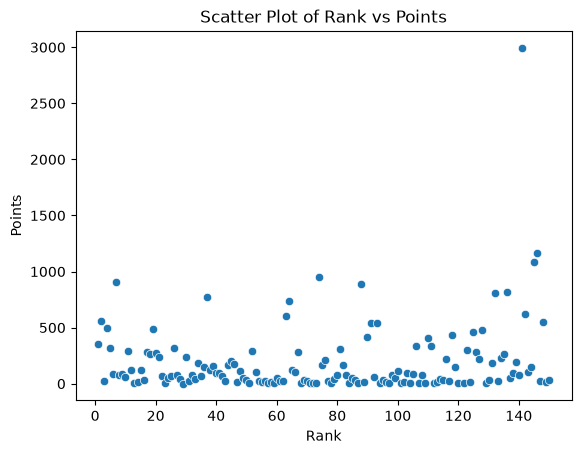

In [79]:
# Use a visualization library to create a scatter plot of the rank vs points of the stories
print("Scatter Plot of Rank vs Points")
print(df_hacker_stories.plot.scatter(x="Rank", y="Points", title="Scatter Plot of Rank vs Points"))

# Label the axes and title of the scatter plot
sns.scatterplot(data=df_hacker_stories, x="Rank", y="Points")
plt.title("Scatter Plot of Rank vs Points")
plt.xlabel("Rank")
plt.ylabel("Points")
plt.show()

# Answering Question 2

What is the relationship between a story popularity versus the comments? 

Scatter Plot of Rank vs Comments
Axes(0.125,0.11;0.775x0.77)


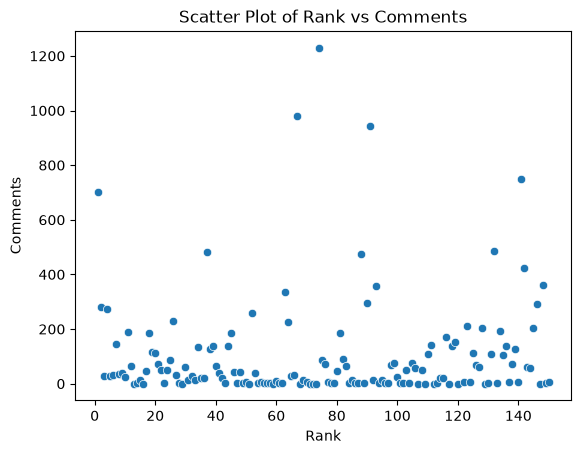

In [80]:
# Use a visualization library to create a scatter plot of the rank vs comments of the stories
print("Scatter Plot of Rank vs Comments")
print(df_hacker_stories.plot.scatter(x="Rank", y="Comments", title="Scatter Plot of Rank vs Comments"))

# Label the axes and title of the scatter plot
sns.scatterplot(data=df_hacker_stories, x="Rank", y="Comments")
plt.title("Scatter Plot of Rank vs Comments")
plt.xlabel("Rank")
plt.ylabel("Comments")
plt.show()

# Answering Question 3

Can we distinguish if a story appears on the front page based on a higher amount of points and comments? Versus if a story appears in the further pages based on a lower amount of points and comments vice versa? 

In [81]:
# Create a new column in the dataframe to group the stories by page number
df_hacker_stories["group_by_page"] = df_hacker_stories["Page"].apply(
    lambda page: "First page" if page == 1 else "Other pages"
)

# Use statistical analysis to compare the points and comments of stories on the first page vs other pages
hacker_page_averages = df_hacker_stories.groupby("group_by_page")[["Points", "Comments"]].mean().round(1)
print(hacker_page_averages)

               Points  Comments
group_by_page                  
First page      199.0      96.7
Other pages     198.6     106.2


# Answer Question 4

Which website domain is among the most popular across all five pages? Can we draw a relationship between website domain popularity against points and comments?


In [82]:
# Create a summary of the stories by domain, including the number of stories, average points, and average comments
hacker_domain_summary = df_hacker_stories.groupby("Domain").agg(
    hacker_stories = ("Title", "count"),
    hacker_average_points = ("Points", "mean"),
    hacker_average_comments = ("Comments", "mean")
).round(1)

# Display the top ten domains containing the most stories
print(hacker_domain_summary.sort_values(
    "hacker_stories", ascending=False
 ).head(10))

                     hacker_stories  hacker_average_points  \
Domain                                                       
github.com                       18                  118.3   
                                  8                   94.8   
twitter.com                       3                  290.0   
spectrum.ieee.org                 2                   15.5   
www.theguardian.com               2                  282.5   
www.anthropic.com                 2                  190.5   
aphyr.com                         1                  432.0   
alnovis.io                        1                    9.0   
benmandrew.com                    1                  240.0   
blog.bosscher.ch                  1                  818.0   

                     hacker_average_comments  
Domain                                        
github.com                              39.6  
                                       153.0  
twitter.com                            191.7  
spectrum.ieee.org   

## Final Conclusion 

Answering question 1 and question 2, we can see that our scatterplots show no plausible relationship between the rank of stories and points or comments. There's no clear positive or negative correlation visible between any of these features so it's safe to assume that these are not significant features in terms of predicting the rank of stories in hacker news domain web scrapping pages. Answering question 3, we can say that Page 1 stories averaged approximately 198.5 points and 96.4 comments compared to the pages 2-5, who averaged together approximately 197.8 points and 105.8 comments. Finally, answering question 4, we can say that the 10 domains containing the most stories are Github(18), twitter(8), and everything else in domains around 2-3. 